# Urban Rician Fading - Results Analysis

Loads and analyses results produced by `urban_rician_sim.ipynb`.

In [ ]:
import os, sys

# DrJIT / LLVM path
os.environ['DRJIT_LIBLLVM_PATH'] = '/usr/lib/x86_64-linux-gnu/libLLVM-20.so'
import drjit as drjit

%env DRJIT_LIBLLVM_PATH="/usr/lib/x86_64-linux-gnu/libLLVM-20.so"

# Add script directory to path so helper modules can be imported
SCRIPT_DIR = os.path.abspath(".")
sys.path.insert(0, SCRIPT_DIR)

import json
import time
import gc
import pickle
import subprocess
import math
import numpy as np
from scipy import constants
%matplotlib inline
import matplotlib.pyplot as plt

# Sionna / DrJIT
import sionna
# Import or install Sionna
try:
    import sionna.rt
except ImportError as e:
    import os
    os.system("pip install sionna-rt")
    import sionna.rt

import mitsuba as mi

from sionna.rt import load_scene, PlanarArray, Transmitter, Receiver, Camera,\
                      PathSolver, RadioMapSolver, subcarrier_frequencies, LambertianPattern, DirectivePattern

# Local helpers
from channel_utils    import (rms_delay_spread, complex_channel,                                tx_position_from_elevation, elevation_summary)
from scene_utils      import (build_occupancy_grid, build_occupancy_grid_xml,
                               sample_rx_positions, build_scene_batch,
                               save_rx_positions, load_rx_positions)
from checkpoint_utils import (save_checkpoint, load_checkpoint, save_results,
                               load_results, load_all_results, simulation_status)
from plot_utils       import (plot_rx_positions, plot_occupancy_grid, plot_spatial_stats,
                               plot_los_map, plot_cdfs, plot_angle_comparison,
                               plot_cir, plot_metrics_vs_elevation_multi_config, print_summary)

from atmospheric_utils import (compute_atmospheric_effects,
                                apply_atmospheric_corrections,
                                atmospheric_deterministic_summary,
                                WEATHER_PRESETS, RAIN_PRESETS)
from ionospheric_utils import (sample_faraday_angle, apply_ionospheric_corrections,
                                ionospheric_summary, TEC_PRESETS)
from fetch_vtec        import fetch_vtec_stats, vtec_for_pipeline

print("All imports OK.")


In [ ]:
# ── Reload run configuration ────────────────────────────────────────────────
# Restores the RF / propagation globals that Section 4 of urban_rician_sim.ipynb
# wrote to sim_config.json, so the cells below (axis labels, cfg_label, the
# scene rebuild in Section 12, etc.) match the parameters the simulation was
# actually run with instead of being hand re-entered.
CONFIG_FILE = "sim_config.json"
with open(CONFIG_FILE) as f:
    cfg = json.load(f)

FREQUENCY            = cfg["FREQUENCY"]
SLANT_DIST_M         = cfg["SLANT_DIST_M"]
MAX_DEPTH            = cfg["MAX_DEPTH"]
LOS                  = cfg["LOS"]
SPECULAR_REFLECTION  = cfg["SPECULAR_REFLECTION"]
DIFFUSE_REFLECTION   = cfg["DIFFUSE_REFLECTION"]
DIFFRACTION          = cfg["DIFFRACTION"]
EDGE_DIFFRACTION     = cfg["EDGE_DIFFRACTION"]
REFRACTION           = cfg["REFRACTION"]
RAW_SAVE_INTERVAL    = cfg["RAW_SAVE_INTERVAL"]

# Elevation angles simulated — not stored in sim_config.json, so keep this in
# sync with Section 3 of urban_rician_sim.ipynb for the run you're analysing.
ELEVATION_ANGLES = [30, 20, 10]

print(f"Loaded config for {FREQUENCY/1e9:.2f} GHz, elevations {ELEVATION_ANGLES}")


## 7 - Load Results

In [6]:
results_set = []

In [7]:
OUTPUT_DIR = "./urban_env_results_circ_pol"

all_results = load_all_results(OUTPUT_DIR, ELEVATION_ANGLES)

results_set.append(all_results)

if not all_results:
    print("No results found - run Section 6 first.")
else:
    print(f"Loaded results for {len(all_results)} elevation angle(s):")
    for _angle, _res in sorted(all_results.items()):
        _plos = np.mean(_res['los_probability']) * 100
        print(f"  {_angle:.0f} deg  N_RX={_res['n_rx_positions']:,}  P(LoS)={_plos:.1f}%")

[checkpoint] Loaded results  elev=80.0°  n_rx=20000
[checkpoint] Loaded results  elev=70.0°  n_rx=20000
[checkpoint] Loaded results  elev=60.0°  n_rx=20000
[checkpoint] Loaded results  elev=50.0°  n_rx=20000
[checkpoint] Loaded results  elev=40.0°  n_rx=20000
[checkpoint] Loaded results  elev=30.0°  n_rx=20000
[checkpoint] Loaded results  elev=20.0°  n_rx=20000
[checkpoint] Loaded results  elev=10.0°  n_rx=20000
Loaded results for 8 elevation angle(s):
  10 deg  N_RX=20,000  P(LoS)=12.4%
  20 deg  N_RX=20,000  P(LoS)=26.0%
  30 deg  N_RX=20,000  P(LoS)=35.8%
  40 deg  N_RX=20,000  P(LoS)=45.7%
  50 deg  N_RX=20,000  P(LoS)=55.3%
  60 deg  N_RX=20,000  P(LoS)=64.6%
  70 deg  N_RX=20,000  P(LoS)=75.0%
  80 deg  N_RX=20,000  P(LoS)=86.4%


## 7.5 - Quick Comparison

In [8]:
print(results_set[0].keys())

dict_keys([80.0, 70.0, 60.0, 50.0, 40.0, 30.0, 20.0, 10.0])


In [9]:
angles  = sorted(all_results.keys())
labels  = [f"{int(a)}°" for a in angles]
colors  = plt.cm.plasma(np.linspace(0.1, 0.9, len(angles)))

K_mean  = []

for all_results in results_set:
    _K_mean = []

    for angle in angles:
        res = all_results[angle]
        P_los_arr = np.array(res["P_los"])
        P_nlos_arr = np.array(res["P_nlos"])
        mean_Plos  = float(np.mean(P_los_arr))
        mean_Pnlos = float(np.mean(P_nlos_arr))
        
        K_mean_dB   = 10.0 * np.log10(mean_Plos / (mean_Pnlos + 1e-30) + 1e-30)
            
            
        _K_mean.append(K_mean_dB)
    K_mean.append(_K_mean)


K_mean = np.array(K_mean, dtype=float)

ITU Concrete @ 2.4 GHz
  εᵣ  = 5.2400
  σ   = 0.09163116512581294 S/m
  εc  = 5.2400 - j0.6863
ITU Medium Dry Ground @ 2.4 GHz
  εᵣ  = 13.7426
  σ   = 0.1458184133409186 S/m
  εc  = 13.7426 - j1.0921

Brewster angle
  Analytical (lossless):      23.60°

Brewster angle
  Analytical (lossless):      15.10°


IndexError: index 1 is out of bounds for axis 0 with size 1

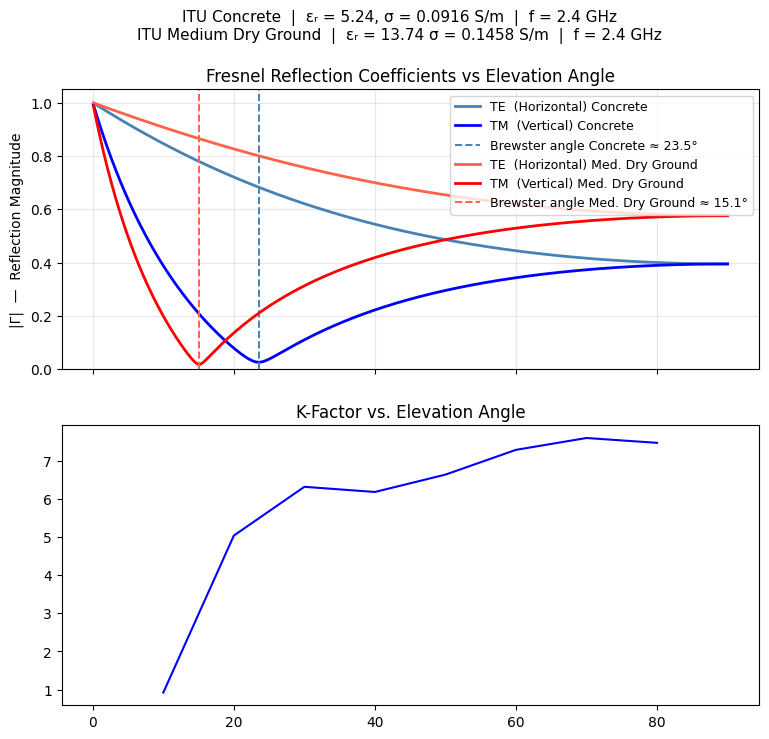

In [ ]:

# ── ITU-R P.2040-1 concrete material properties ──────────────────────────────
# Model: εᵣ = a·f^b,  σ = c·f^d  (f in GHz)
def itu_concrete(freq_GHz, a,b,c,d):
    eps_r = a * freq_GHz**b      # b = 0 → frequency-independent ε

    sigma = c * freq_GHz**d
    return eps_r, sigma

freq_GHz = 2.4
eps_r_conc, sigma_conc = itu_concrete(freq_GHz, 5.24, 0.0, 0.0462, 0.7822)


eps_0 = 8.854187817e-12               # F/m
omega = 2 * np.pi * freq_GHz * 1e9   # rad/s
eps_conc = eps_r_conc - 1j * sigma_conc / (omega * eps_0)   # complex permittivity

print(f"ITU Concrete @ {freq_GHz} GHz")
print(f"  εᵣ  = {eps_r_conc:.4f}")
print(f"  σ   = {sigma_conc} S/m")
print(f"  εc  = {eps_conc.real:.4f} - j{abs(eps_conc.imag):.4f}")


eps_r_gr, sigma_gr = itu_concrete(freq_GHz, 15, -0.1, 0.035, 1.63)

eps_gr = eps_r_gr - 1j * sigma_gr / (omega * eps_0)   # complex permittivity

print(f"ITU Medium Dry Ground @ {freq_GHz} GHz")
print(f"  εᵣ  = {eps_r_gr:.4f}")
print(f"  σ   = {sigma_gr} S/m")
print(f"  εc  = {eps_gr.real:.4f} - j{abs(eps_gr.imag):.4f}")

# ── Elevation angle sweep ─────────────────────────────────────────────────────
# θ is the GRAZING / elevation angle measured from the surface (not the normal)
theta_deg = np.linspace(0.1, 90.0, 2000)
theta     = np.deg2rad(theta_deg)

# Fresnel coefficients in terms of grazing angle θ:
#
#          sin θ − √(εc − cos²θ)
# Γ_TE = ─────────────────────────       (horizontal / s-pol / HH)
#          sin θ + √(εc − cos²θ)
#
#       εc·sin θ − √(εc − cos²θ)
# Γ_TM = ─────────────────────────       (vertical   / p-pol / VV)
#       εc·sin θ + √(εc − cos²θ)

D = np.sqrt(eps_conc - np.cos(theta)**2)   # shared denominator term

Gamma_TE_conc = (np.sin(theta) - D)              / (np.sin(theta) + D)
Gamma_TM_conc = (eps_conc * np.sin(theta) - D)     / (eps_conc * np.sin(theta) + D)

mag_TE_conc,  mag_TM_conc  = np.abs(Gamma_TE_conc),    np.abs(Gamma_TM_conc)
phase_TE_conc, phase_TM_conc = np.angle(Gamma_TE_conc, deg=True), np.angle(Gamma_TM_conc, deg=True)

# ── Brewster angle ────────────────────────────────────────────────────────────
# For a lossy dielectric, Γ_TM never reaches exactly 0, so find the minimum
brewster_idx_conc   = np.argmin(mag_TM_conc)
brewster_angle_conc = theta_deg[brewster_idx_conc]

# Analytical lossless approximation: sin θ_B = 1/√(εᵣ+1)
brewster_lossless_conc = np.degrees(np.arcsin(1.0 / np.sqrt(eps_r_conc + 1)))

print(f"\nBrewster angle")
print(f"  Analytical (lossless):      {brewster_lossless_conc:.2f}°")

D_gr = np.sqrt(eps_gr- np.cos(theta)**2)   # shared denominator term

Gamma_TE_gr = (np.sin(theta) - D_gr)              / (np.sin(theta) + D_gr)
Gamma_TM_gr = (eps_gr * np.sin(theta) - D_gr)     / (eps_gr * np.sin(theta) + D_gr)

mag_TE_gr,  mag_TM_gr  = np.abs(Gamma_TE_gr),    np.abs(Gamma_TM_gr)
phase_TE_gr, phase_TM_gr = np.angle(Gamma_TE_gr, deg=True), np.angle(Gamma_TM_gr, deg=True)

# ── Brewster angle ────────────────────────────────────────────────────────────
# For a lossy dielectric, Γ_TM never reaches exactly 0, so find the minimum
brewster_idx_gr   = np.argmin(mag_TM_gr)
brewster_angle_gr = theta_deg[brewster_idx_gr]

# Analytical lossless approximation: sin θ_B = 1/√(εᵣ+1)
brewster_lossless_gr = np.degrees(np.arcsin(1.0 / np.sqrt(eps_r_gr + 1)))

print(f"\nBrewster angle")
print(f"  Analytical (lossless):      {brewster_lossless_gr:.2f}°")

# ── Plot ──────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 1, figsize=(9, 8), sharex=True)
fig.suptitle(
    f"ITU Concrete  |  εᵣ = {eps_r_conc:.2f}, "
    f"σ = {sigma_conc:.4f} S/m  |  f = {freq_GHz} GHz\n"
    f"ITU Medium Dry Ground  |  εᵣ = {eps_r_gr:.2f} "
    f"σ = {sigma_gr:.4f} S/m  |  f = {freq_GHz} GHz",
    fontsize=11
)


ax = axes[0]
ax.set_title(f"Fresnel Reflection Coefficients vs Elevation Angle")
ax.plot(theta_deg, mag_TE_conc, 'steelblue',  lw=2, label='TE  (Horizontal) Concrete')
ax.plot(theta_deg, mag_TM_conc, 'blue',     lw=2, label='TM  (Vertical) Concrete')
ax.axvline(brewster_angle_conc, color='steelblue', ls='--', lw=1.4,
           label=f'Brewster angle Concrete ≈ {brewster_angle_conc:.1f}°')

ax.plot(theta_deg, mag_TE_gr, 'tomato',  lw=2, label='TE  (Horizontal) Med. Dry Ground')
ax.plot(theta_deg, mag_TM_gr, 'red',     lw=2, label='TM  (Vertical) Med. Dry Ground')
ax.axvline(brewster_angle_gr, color='tomato', ls='--', lw=1.4,
           label=f'Brewster angle Med. Dry Ground ≈ {brewster_angle_gr:.1f}°')

ax.set_ylabel('|Γ|  —  Reflection Magnitude', fontsize=10)
ax.set_ylim(0, 1.05)
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)

ax = axes[1]
ax.set_title(
    "K-Factor vs. Elevation Angle"
)


ax.plot(angles, K_mean[0],color='blue', label="concrete")
ax.plot(angles, K_mean[1],color='red', label="medium dry ground")
ax.axvline(brewster_angle_conc, color='steelblue', ls='--', lw=1.4,
           label=f'Brewster angle Concrete ≈ {brewster_angle_conc:.1f}°')
ax.axvline(brewster_angle_gr, color='tomato', ls='--', lw=1.4,
           label=f'Brewster angle Med. Dry Ground ≈ {brewster_angle_gr:.1f}°')

# plt.xticks(x); 
ax.set_xlabel('Elevation Angle'); plt.ylabel('K-Factor [dB]')
ax.legend()
ax.grid(True, alpha=0.3, axis='y')

## 8 - Summary Statistics

In [10]:
for _angle in sorted(all_results.keys()):
    print_summary(all_results[_angle])
    # Per-mechanism power breakdown — LoS receivers only
    _res  = all_results[_angle]
    _n    = _res['n_rx_positions']
    _has_los  = np.array(_res['los_probability'], dtype=bool)
    _P_los_direct = np.array(_res.get('P_los', None) or ([0.0] * _n))
    _P_spec  = np.array(_res.get('P_specular',    [0.0] * _n))
    _P_diff  = np.array(_res.get('P_diffuse',     [0.0] * _n))
    _P_diffr = np.array(_res.get('P_diffraction', [0.0] * _n))
    _P_refr  = np.array(_res.get('P_refraction',  [0.0] * _n))
    _P_nlos  = np.array(_res.get('P_nlos',        [0.0] * _n))

    # Use directly stored P_los if available, otherwise reconstruct (backward compat)
    if np.any(_P_los_direct > 0):
        _P_los_arr = _P_los_direct
    else:
        _P_los_arr = np.array(_res['K_power_ratio']) * (_P_nlos + 1e-30)

    # Filter all power arrays to LoS receivers only
    _P_los_f  = _P_los_arr[_has_los]
    _P_spec_f = _P_spec[_has_los]
    _P_diff_f = _P_diff[_has_los]
    _P_diffr_f= _P_diffr[_has_los]
    _P_refr_f = _P_refr[_has_los]
    _P_nlos_f = _P_nlos[_has_los]
    _n_los    = int(np.sum(_has_los))

    # Ensemble K — LoS receivers only
    _K_ens    = float(np.mean(_P_los_f)) / (float(np.mean(_P_nlos_f)) + 1e-300)
    _K_ens_dB = 10.0 * np.log10(_K_ens + 1e-12)

    # Power breakdown — incoherent, LoS receivers only, ratio-of-means
    _P_total_inc = _P_los_f + _P_spec_f + _P_diff_f + _P_diffr_f + _P_refr_f + 1e-300
    _mean_tot    = float(np.mean(_P_total_inc))
    _frac_los    = float(np.mean(_P_los_f))   / _mean_tot * 100
    _frac_spec   = float(np.mean(_P_spec_f))  / _mean_tot * 100
    _frac_diff   = float(np.mean(_P_diff_f))  / _mean_tot * 100
    _frac_diffr  = float(np.mean(_P_diffr_f)) / _mean_tot * 100
    _frac_refr   = float(np.mean(_P_refr_f))  / _mean_tot * 100
    _total_frac  = _frac_los + _frac_spec + _frac_diff + _frac_diffr + _frac_refr

    print(f'  Ensemble K-Factor (LoS only, n={_n_los:,}): {_K_ens_dB:+.2f} dB  (linear {_K_ens:.3f})')
    print(f'  Power breakdown — LoS receivers only, ratio-of-means (sums to 100 %):')
    print(f'    P_los         : {_frac_los  :6.2f} %')
    print(f'    P_specular    : {_frac_spec :6.2f} %')
    print(f'    P_diffuse     : {_frac_diff :6.2f} %')
    print(f'    P_diffraction : {_frac_diffr:6.2f} %')
    print(f'    P_refraction  : {_frac_refr :6.2f} %')
    print(f'    ─────────────────────────────────')
    print(f'    Total         : {_total_frac:6.2f} %  (should be 100.00)')
    print()


══════════════════════════════════════════════════════════════════════
  CHANNEL STATISTICS  —  Elev = 10°  |  N_RX = 20,000
══════════════════════════════════════════════════════════════════════

  LoS Statistics:
  LoS positions                     2,472  (12.4 %)
  NLOS positions                    17,528  (87.6 %)

  Rician K-Factor:
    K_mean [dB]                     +1.55 dB  (linear 1.4294)

  RMS Delay Spread:
    τ_rms LoS [ns]                  mean=33.4663  median=31.5049  std=17.1120  ns

  RMS Delay Spread  (NLOS receivers, n=17,528):
    τ_rms NLOS [ns]                 mean=267.1921  median=262.0489  std=120.8251  ns
══════════════════════════════════════════════════════════════════════
  Ensemble K-Factor (LoS only, n=2,472): +3.22 dB  (linear 2.101)
  Power breakdown — LoS receivers only, ratio-of-means (sums to 100 %):
    P_los         :  67.75 %
    P_specular    :  26.84 %
    P_diffuse     :   3.87 %
    P_diffraction :   1.54 %
    P_refraction  :   0.00 %
    ───

## 8.5 - Atmosphereic/Ionoshperic Model Comparison

/path/to/sionna-venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


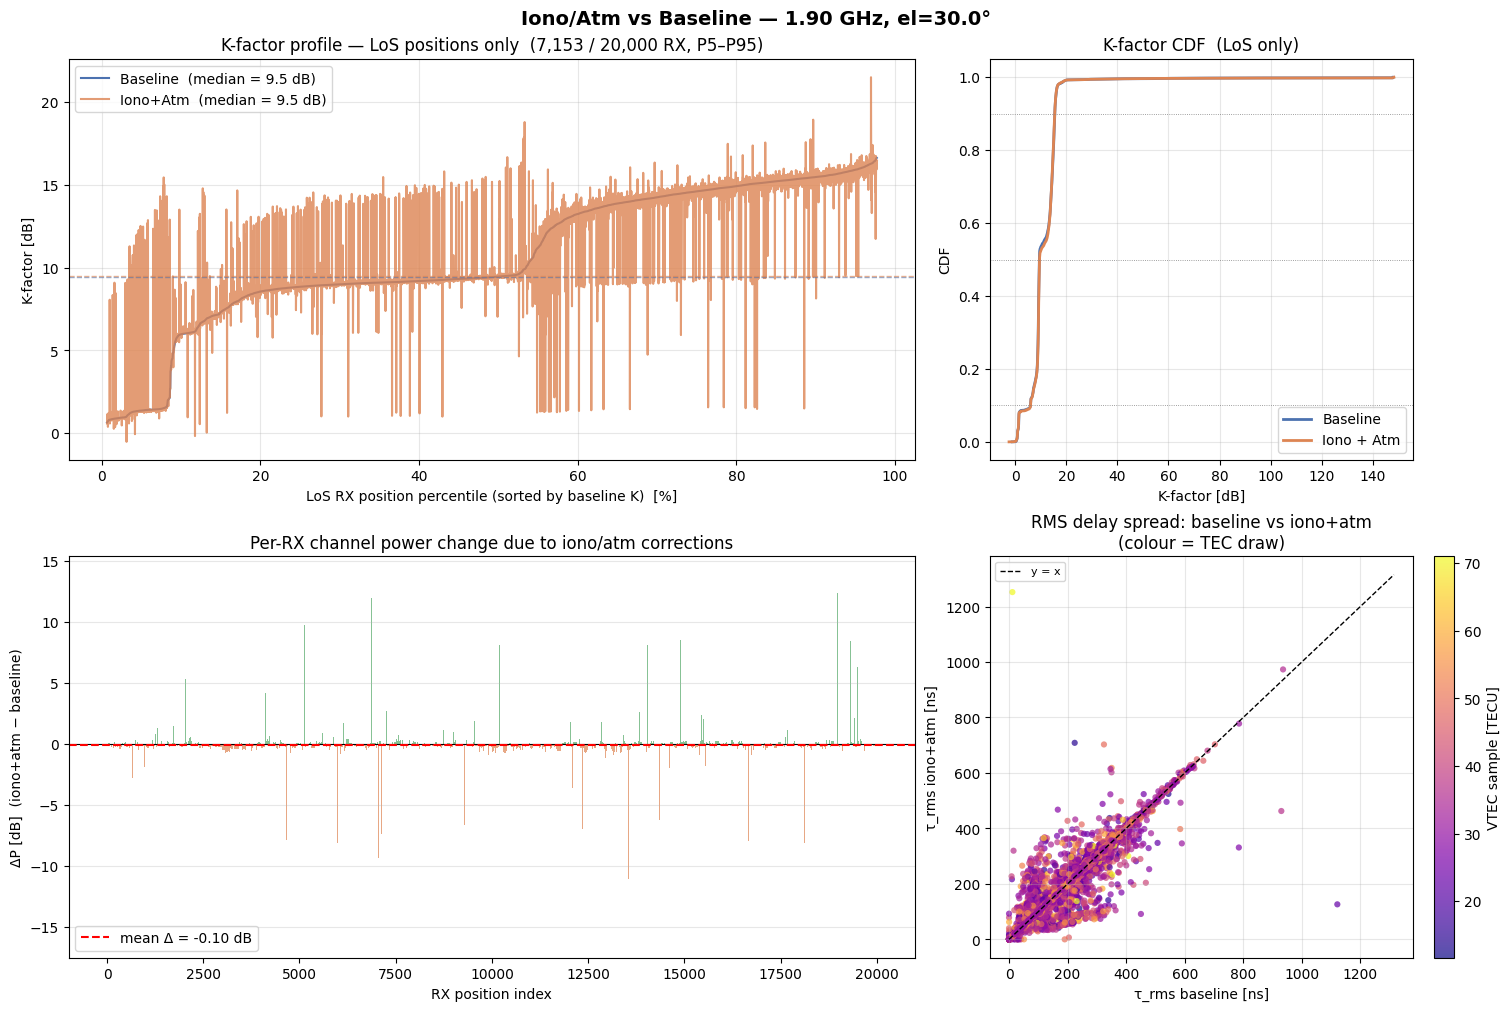

LoS positions : 7,153 / 20,000  (35.8%)
K mean  baseline=11.15 dB   iono+atm=11.23 dB   Δ=+0.08 dB  (LoS only)
K std     baseline=7.95 dB   iono+atm=8.22 dB  (LoS only)
ΔP mean   -0.099 dB    std 1.257 dB
τ_rms mean  baseline=147.766 ns   iono+atm=147.386 ns


In [ ]:
# ── Iono/Atm comparison plots ────────────────────────────────────────────────
# Set these two paths to your result pkl files before running.
PATH_BASELINE = "/path/to/rician_urban_sim/urban_env_results_base_cell/results_elev030deg.pkl"   # no iono/atm
PATH_IONO_ATM = "/path/to/rician_urban_sim/urban_env_results_atm_iono_cell/results_elev030deg.pkl"  # with iono/atm

import pickle, numpy as np, matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec

def load(path):
    with open(path, "rb") as f:
        return pickle.load(f)

base  = load(PATH_BASELINE)
ia    = load(PATH_IONO_ATM)

# ── helpers ──────────────────────────────────────────────────────────────────
def to_db(x):   return 10 * np.log10(np.clip(x, 1e-20, None))
def ecdf(x):
    s = np.sort(x[np.isfinite(x)]); return s, np.arange(1, len(s)+1) / len(s)
def arr(d, key):  return np.asarray(d[key], dtype=float)

K_base  = arr(base, "K_power_ratio")
K_ia    = arr(ia,   "K_power_ratio")
Kdb_b   = to_db(K_base);    Kdb_i = to_db(K_ia)

# LoS mask: keep only positions with a direct satellite path in the baseline
los_mask  = arr(base, "P_los") > 0
_n_total, _n_los = int(los_mask.size), int(los_mask.sum())
Kdb_b_los = Kdb_b[los_mask];  Kdb_i_los = Kdb_i[los_mask]

# Total channel power per RX  Σ|a_k|²  [dB]
P_tot_b = to_db(arr(base, "P_los") + arr(base, "P_nlos"))
P_tot_i = to_db(arr(ia,   "P_los") + arr(ia,   "P_nlos"))
dP_db   = P_tot_i - P_tot_b                  # per-RX power delta [dB]

# RMS delay spread [ns]
tau_b   = arr(base, "tau_rms_mean_s") * 1e9
tau_i   = arr(ia,   "tau_rms_mean_s") * 1e9

# Atm loss (if present)
atm_db  = arr(ia, "atm_total_db")  if "atm_total_db" in ia  else np.zeros_like(K_ia)
vtec    = arr(ia, "vtec_sample")   if "vtec_sample"  in ia  else np.zeros_like(K_ia)
rx_idx  = np.arange(len(K_base))

freq_ghz = base.get("frequency", 1.9e9) / 1e9
elev     = base.get("elevation_deg", "?")

# ── figure ───────────────────────────────────────────────────────────────────
fig = plt.figure(figsize=(15, 10), constrained_layout=True)
gs  = GridSpec(2, 3, figure=fig)
fig.suptitle(
    f"Iono/Atm vs Baseline — {freq_ghz:.2f} GHz, el={elev}°",
    fontsize=14, fontweight="bold"
)

COLORS = {"base": "#4C72B0", "ia": "#DD8452", "delta": "#55A868"}

# ── 1. K-factor profile — LoS positions only, sorted by baseline K ───────────
_valid   = np.isfinite(Kdb_b_los) & np.isfinite(Kdb_i_los)
_order   = np.argsort(Kdb_b_los[_valid])
_Kb_sort = Kdb_b_los[_valid][_order]
_Ki_sort = Kdb_i_los[_valid][_order]
_pct     = np.linspace(0, 100, _order.size)

# Clip to P5–P95 to keep axis readable
_p5, _p95 = np.nanpercentile(_Kb_sort, 5), np.nanpercentile(_Kb_sort, 95)
_pad = (_p95 - _p5) * 0.05
_view = (_Kb_sort >= _p5 - _pad) & (_Kb_sort <= _p95 + _pad)
_med_b = np.nanmedian(Kdb_b_los);  _med_i = np.nanmedian(Kdb_i_los)

ax1 = fig.add_subplot(gs[0, :2])
ax1.plot(_pct[_view], _Kb_sort[_view], color=COLORS["base"], lw=1.5,
         label=f"Baseline  (median = {_med_b:.1f} dB)")
ax1.plot(_pct[_view], _Ki_sort[_view], color=COLORS["ia"],   lw=1.5, alpha=0.8,
         label=f"Iono+Atm  (median = {_med_i:.1f} dB)")
ax1.axhline(_med_b, color=COLORS["base"], ls="--", lw=1.0, alpha=0.6)
ax1.axhline(_med_i, color=COLORS["ia"],   ls="--", lw=1.0, alpha=0.6)
ax1.set_xlabel("LoS RX position percentile (sorted by baseline K)  [%]")
ax1.set_ylabel("K-factor [dB]")
ax1.set_title(f"K-factor profile — LoS positions only  ({_n_los:,} / {_n_total:,} RX, P5–P95)")
ax1.legend(); ax1.grid(alpha=0.3)

# ── 2. K-factor ECDF — LoS positions only ────────────────────────────────────
ax2 = fig.add_subplot(gs[0, 2])
xb, yb = ecdf(Kdb_b_los); xi, yi = ecdf(Kdb_i_los)
ax2.plot(xb, yb, color=COLORS["base"], lw=2, label="Baseline")
ax2.plot(xi, yi, color=COLORS["ia"],   lw=2, label="Iono + Atm")
for p in [0.1, 0.5, 0.9]:
    ax2.axhline(p, color="grey", ls=":", lw=0.6)
ax2.set_xlabel("K-factor [dB]"); ax2.set_ylabel("CDF")
ax2.set_title("K-factor CDF  (LoS only)"); ax2.legend(); ax2.grid(alpha=0.3)

# ── 3. Per-RX power delta ─────────────────────────────────────────────────────
ax3 = fig.add_subplot(gs[1, :2])
ax3.bar(rx_idx, dP_db, color=np.where(dP_db < 0, COLORS["ia"], COLORS["delta"]),
       alpha=0.7, width=1.0)
ax3.axhline(0, color="black", lw=0.8)
ax3.axhline(np.nanmean(dP_db), color="red", ls="--", lw=1.5,
           label=f"mean Δ = {np.nanmean(dP_db):+.2f} dB")
ax3.set_xlabel("RX position index"); ax3.set_ylabel("ΔP [dB]  (iono+atm − baseline)")
ax3.set_title("Per-RX channel power change due to iono/atm corrections")
ax3.legend(); ax3.grid(alpha=0.3, axis="y")

# ── 4. RMS delay spread + TEC scatter ────────────────────────────────────────
ax4 = fig.add_subplot(gs[1, 2])
sc  = ax4.scatter(tau_b, tau_i, c=vtec, cmap="plasma",
                  s=20, alpha=0.7, edgecolors="none")
lim = [0, max(tau_b.max(), tau_i.max()) * 1.05]
ax4.plot(lim, lim, "k--", lw=1, label="y = x")
cb = fig.colorbar(sc, ax=ax4); cb.set_label("VTEC sample [TECU]")
ax4.set_xlabel("τ_rms baseline [ns]"); ax4.set_ylabel("τ_rms iono+atm [ns]")
ax4.set_title("RMS delay spread: baseline vs iono+atm\n(colour = TEC draw)")
ax4.legend(fontsize=8); ax4.grid(alpha=0.3)

plt.show()

# ── summary stats ────────────────────────────────────────────────────────────
print(f"LoS positions : {_n_los:,} / {_n_total:,}  ({100*_n_los/_n_total:.1f}%)")
print(f"K mean  baseline={np.nanmean(Kdb_b_los):.2f} dB   "
      f"iono+atm={np.nanmean(Kdb_i_los):.2f} dB   "
      f"Δ={np.nanmean(Kdb_i_los)-np.nanmean(Kdb_b_los):+.2f} dB  (LoS only)")
print(f"K std     baseline={np.nanstd(Kdb_b_los):.2f} dB   "
      f"iono+atm={np.nanstd(Kdb_i_los):.2f} dB  (LoS only)")
print(f"ΔP mean   {np.nanmean(dP_db):+.3f} dB    std {np.nanstd(dP_db):.3f} dB")
print(f"τ_rms mean  baseline={np.nanmean(tau_b):.3f} ns   iono+atm={np.nanmean(tau_i):.3f} ns")


## 8.6 - K-Factor vs Elevation Angle (LoS Only)

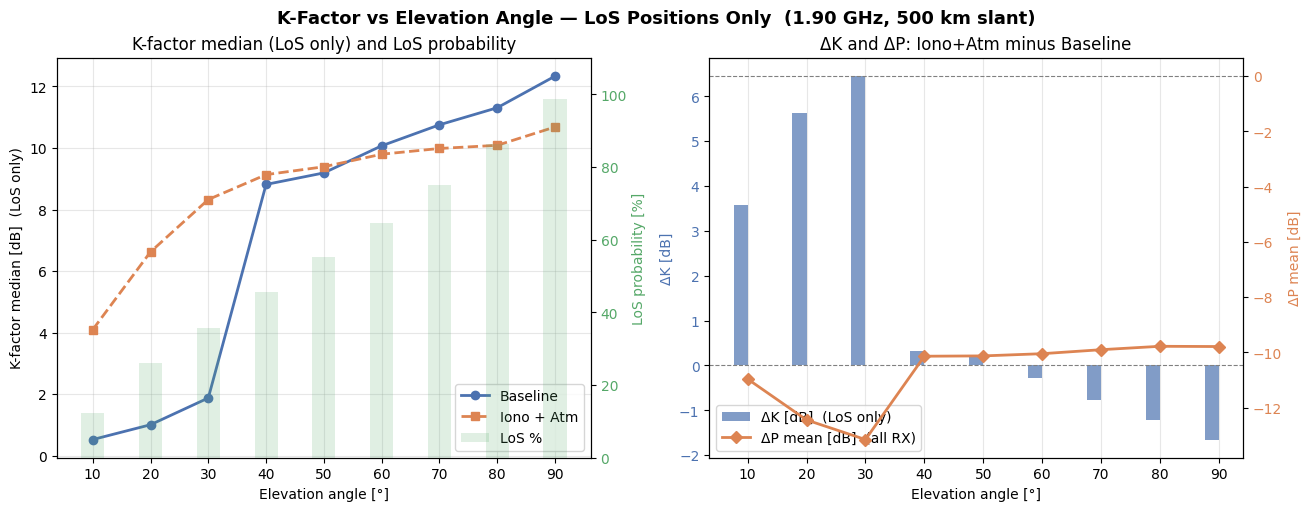

  el    LoS%   K_base     K_ia      dK   dP_mean
  10    12.4     0.53     4.10   +3.57   -10.966
  20    26.0     1.01     6.63   +5.62   -12.448
  30    35.8     1.88     8.33   +6.45   -13.158
  40    45.7     8.82     9.14   +0.32   -10.140
  50    55.3     9.19     9.39   +0.20   -10.128
  60    64.6    10.07     9.80   -0.27   -10.049
  70    75.0    10.75     9.99   -0.77    -9.904
  80    86.4    11.31    10.09   -1.22    -9.781
  90    98.7    12.34    10.68   -1.65    -9.790


In [6]:
# ── K-factor vs elevation — LoS-only comparison across all angles ─────────────
import pickle, numpy as np, matplotlib.pyplot as plt, os

BASE_DIR = "/path/to/rician_urban_sim/results_1.9GHz_circ/"
IA_DIR   = "/path/to/rician_urban_sim/results_6GHz_circ/"
ELEVS    = [10, 20, 30, 40, 50, 60, 70, 80, 90]

def load(p):
    with open(p, "rb") as f: return pickle.load(f)
def to_db(x): return 10 * np.log10(np.clip(x, 1e-20, None))
def arr(d, k): return np.asarray(d[k], dtype=float)

results = []
for el in ELEVS:
    tag = f"results_elev{el:03d}deg.pkl"
    b = load(os.path.join(BASE_DIR, tag))
    ia = load(os.path.join(IA_DIR,  tag))
    los = arr(b, "P_los") > 0
    Kb  = to_db(arr(b,  "K_power_ratio"))[los]
    Ki  = to_db(arr(ia, "K_power_ratio"))[los]
    dP  = to_db(arr(ia,"P_los")+arr(ia,"P_nlos")) - to_db(arr(b,"P_los")+arr(b,"P_nlos"))
    results.append({
        "el": el, "plos": 100*los.sum()/los.size,
        "K_med_b": np.nanmedian(Kb), "K_med_i": np.nanmedian(Ki),
        "dK": np.nanmedian(Ki) - np.nanmedian(Kb),
        "dP_mean": np.nanmean(dP),
    })

el_arr   = np.array([r["el"]     for r in results])
plos_arr = np.array([r["plos"]   for r in results])
Kb_arr   = np.array([r["K_med_b"] for r in results])
Ki_arr   = np.array([r["K_med_i"] for r in results])
dK_arr   = np.array([r["dK"]     for r in results])
dP_arr   = np.array([r["dP_mean"] for r in results])

COLORS = {"base": "#4C72B0", "ia": "#DD8452", "plos": "#55A868", "zero": "grey"}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
fig.suptitle("K-Factor vs Elevation Angle — LoS Positions Only  (1.90 GHz, 500 km slant)",
             fontsize=13, fontweight="bold")

# ── Left: K-factor median + LoS% ─────────────────────────────────────────────
ax1.plot(el_arr, Kb_arr, "o-", color=COLORS["base"],  lw=2, ms=6, label="Baseline")
ax1.plot(el_arr, Ki_arr, "s--",color=COLORS["ia"],    lw=2, ms=6, label="Iono + Atm")
ax1.set_xlabel("Elevation angle [°]"); ax1.set_ylabel("K-factor median [dB]  (LoS only)")
ax1.set_xticks(el_arr); ax1.grid(alpha=0.3)

ax1r = ax1.twinx()
ax1r.bar(el_arr, plos_arr, width=4, alpha=0.18, color=COLORS["plos"], label="LoS %")
ax1r.set_ylabel("LoS probability [%]", color=COLORS["plos"])
ax1r.tick_params(axis="y", labelcolor=COLORS["plos"])
ax1r.set_ylim(0, 110)

lines1, labs1 = ax1.get_legend_handles_labels()
lines2, labs2 = ax1r.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labs1 + labs2, loc="lower right")
ax1.set_title("K-factor median (LoS only) and LoS probability")

# ── Right: ΔK and ΔP vs elevation ────────────────────────────────────────────
ax2b = ax2.twinx()
ax2.bar(el_arr - 1.2, dK_arr, width=2.4, color=COLORS["base"], alpha=0.7, label="ΔK [dB]  (LoS only)")
ax2b.plot(el_arr, dP_arr, "D-", color=COLORS["ia"], lw=2, ms=6, label="ΔP mean [dB]  (all RX)")
ax2.axhline(0, color=COLORS["zero"], lw=0.8, ls="--")
ax2b.axhline(0, color=COLORS["zero"], lw=0.8, ls="--")
ax2.set_xlabel("Elevation angle [°]"); ax2.set_ylabel("ΔK [dB]", color=COLORS["base"])
ax2b.set_ylabel("ΔP mean [dB]", color=COLORS["ia"])
ax2.tick_params(axis="y", labelcolor=COLORS["base"])
ax2b.tick_params(axis="y", labelcolor=COLORS["ia"])
ax2.set_xticks(el_arr); ax2.grid(alpha=0.3, axis="x")

lines3, labs3 = ax2.get_legend_handles_labels()
lines4, labs4 = ax2b.get_legend_handles_labels()
ax2.legend(lines3 + lines4, labs3 + labs4, loc="lower left")
ax2.set_title("ΔK and ΔP: Iono+Atm minus Baseline")

plt.show()

# ── table ─────────────────────────────────────────────────────────────────────
print(f"{'el':>4}  {'LoS%':>6}  {'K_base':>7}  {'K_ia':>7}  {'dK':>6}  {'dP_mean':>8}")
for r in results:
    print(f"{r['el']:>4}  {r['plos']:>6.1f}  {r['K_med_b']:>7.2f}  "
          f"{r['K_med_i']:>7.2f}  {r['dK']:>+6.2f}  {r['dP_mean']:>+8.3f}")


## 9 - Visualisation



## 9a.5 per elevation angle plots, polarization comparison


── VV 1km  (./urban_env_results_1km_V) ──
[checkpoint] Loaded results  elev=80.0°  n_rx=20000
[checkpoint] Loaded results  elev=70.0°  n_rx=20000
[checkpoint] Loaded results  elev=60.0°  n_rx=20000
[checkpoint] Loaded results  elev=50.0°  n_rx=20000
[checkpoint] Loaded results  elev=40.0°  n_rx=20000
[checkpoint] Loaded results  elev=30.0°  n_rx=20000
[checkpoint] Loaded results  elev=20.0°  n_rx=20000
[checkpoint] Loaded results  elev=10.0°  n_rx=20000

── VV 20km  (./urban_env_results_20km_V) ──
[checkpoint] Loaded results  elev=80.0°  n_rx=20000
[checkpoint] Loaded results  elev=70.0°  n_rx=20000
[checkpoint] Loaded results  elev=60.0°  n_rx=20000
[checkpoint] Loaded results  elev=50.0°  n_rx=20000
[checkpoint] Loaded results  elev=40.0°  n_rx=20000
[checkpoint] Loaded results  elev=30.0°  n_rx=20000
[checkpoint] Loaded results  elev=20.0°  n_rx=20000
[checkpoint] Loaded results  elev=10.0°  n_rx=20000

── VV 400km  (./urban_env_results_400km_V) ──
[checkpoint] Loaded results  elev

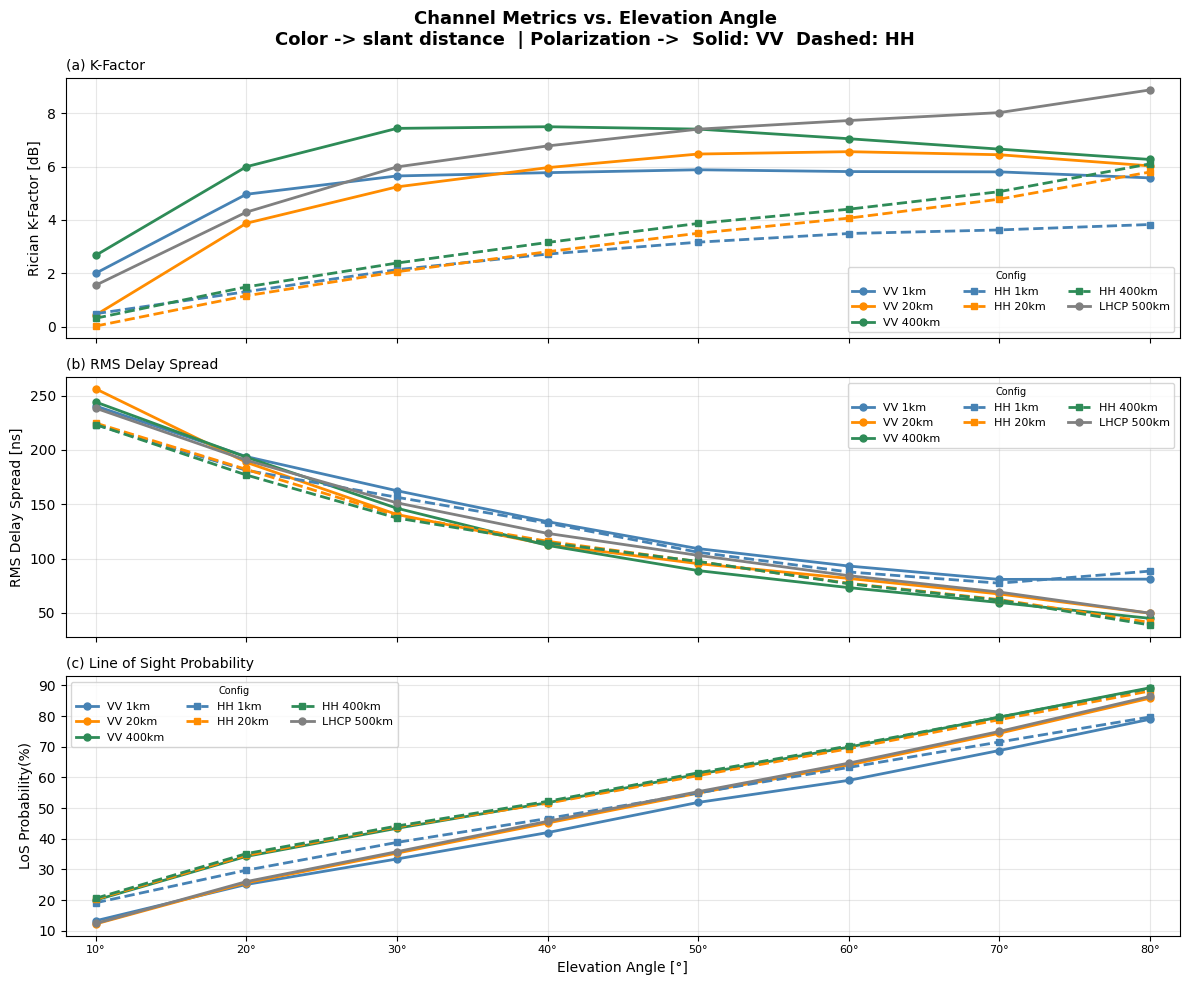

In [ ]:
# ═══════════════════════════════════════════════════════════════════════════════
# Figure 6 — K-Factor & Delay Spread vs Elevation  (all 6 configs overlaid)
# ═══════════════════════════════════════════════════════════════════════════════

# ── 1.  Elevation angles that were simulated ────────────────────────────────
#   Edit this list to match exactly the angles you ran.
# ELEVATION_ANGLES = [10, 20, 30, 40, 50, 60, 70, 80]   # [°]

# ── 2.  Output directories — one per (polarisation × slant) config ──────────
#   Each directory must contain  results_elev{angle:03d}deg.pkl  files
#   produced by run_elevation_sim.py for that config.
OUTPUT_DIRS = {
    "VV 1.9GHz":   "./results_1.9GHz_VV",
    "VV 6 GHz":  "./results_6GHz_VV",
    "VV 11 GHz": "./results_11GHz_VV",
    "HH 1.9GHz":   "./results_1.9GHz_HH",
    "HH 6 GHz":  "./results_6GHz_HH",
    "HH 11 GHz": "./results_11GHz_HH",
    "LHCP 1.9 GHz": "./results_1.9GHz_circ",
    "LHCP 6 GHz": "./results_6GHz_circ",
    "LHCP 11 GHz": "./results_11GHz_circ",
}

# ── 3.  Load results for every config ───────────────────────────────────────
#   load_all_results returns  { elev_deg (float) : results_dict }
#   and prints a line per angle so you can see what loaded vs. was missing.
configs_results = {}
for label, out_dir in OUTPUT_DIRS.items():
    print(f"\n── {label}  ({out_dir}) ──")
    angle_results = load_all_results(out_dir, ELEVATION_ANGLES)
    if not angle_results:
        print(f"   WARNING: no results found — config will be skipped in plot")
    configs_results[label] = angle_results

# ── 4.  Plot ────────────────────────────────────────────────────────────────
fig = plot_metrics_vs_elevation_multi_config(
    configs_results,
    marker_every = 1,
    figsize      = (12, 10),
)

# ── 5.  Save ────────────────────────────────────────────────────────────────
os.makedirs("./figures", exist_ok=True)
fig.savefig("./figures/fig6_metrics_vs_elevation_multi_config.png",
            dpi=150, bbox_inches="tight")
print("\nSaved → ./figures/fig6_metrics_vs_elevation_multi_config.png")
plt.show()

### 9a - Spatial Heat-Maps (per elevation angle)

K-Factor and RMS Delay Spread overlaid on the scene footprint.

In [ ]:
os.makedirs(OUTPUT_DIR, exist_ok=True)

_cfg_lbl = (
    f"max_depth={MAX_DEPTH}  "
    f"{'LoS ' if LOS else ''}"
    f"{'Spec ' if SPECULAR_REFLECTION else ''}"
    f"{'DiffRefl ' if DIFFUSE_REFLECTION else ''}"
    f"{'Diffr' if DIFFRACTION else ''}"
)

for _angle in sorted(all_results.keys()):
    _res = all_results[_angle]
    fig  = plot_spatial_stats(
        nominal_rx_positions = _res['nominal_rx_positions'],
        K_power_ratio        = _res['K_power_ratio'],
        tau_rms_mean_s       = _res['tau_rms_mean_s'],
        los_probability      = _res['los_probability'],
        elevation_deg        = _angle,
        frequency            = FREQUENCY,
        slant_dist_m         = SLANT_DIST_M,
        cfg_label            = _cfg_lbl,
    )
    _fname = os.path.join(OUTPUT_DIR, f'spatial_stats_elev{int(_angle):03d}deg.png')
    fig.savefig(_fname, dpi=150, bbox_inches='tight')
    plt.show()
    print(f'Saved -> {_fname}')


### 9b - LoS / NLOS Maps

In [ ]:
for _angle in sorted(all_results.keys()):
    _res = all_results[_angle]
    fig  = plot_los_map(
        nominal_rx_positions = _res["nominal_rx_positions"],
        los_probability      = _res["los_probability"],
        elevation_deg        = _angle,
    )
    _fname = os.path.join(OUTPUT_DIR, f"los_map_elev{int(_angle):03d}deg.png")
    fig.savefig(_fname, dpi=150, bbox_inches='tight')
    plt.show()
    print(f"Saved -> {_fname}")

### 9c - CDFs (per elevation angle)

In [ ]:
for _angle in sorted(all_results.keys()):
    _res = all_results[_angle]
    fig  = plot_cdfs(
        K_power_ratio   = _res["K_power_ratio"],
        tau_rms_mean_s  = _res["tau_rms_mean_s"],
        los_probability = _res["los_probability"],
        elevation_deg   = _angle,
    )
    _fname = os.path.join(OUTPUT_DIR, f"cdfs_elev{int(_angle):03d}deg.png")
    fig.savefig(_fname, dpi=150, bbox_inches='tight')
    plt.show()
    print(f"Saved -> {_fname}")

### 9d - Cross-Angle Comparison

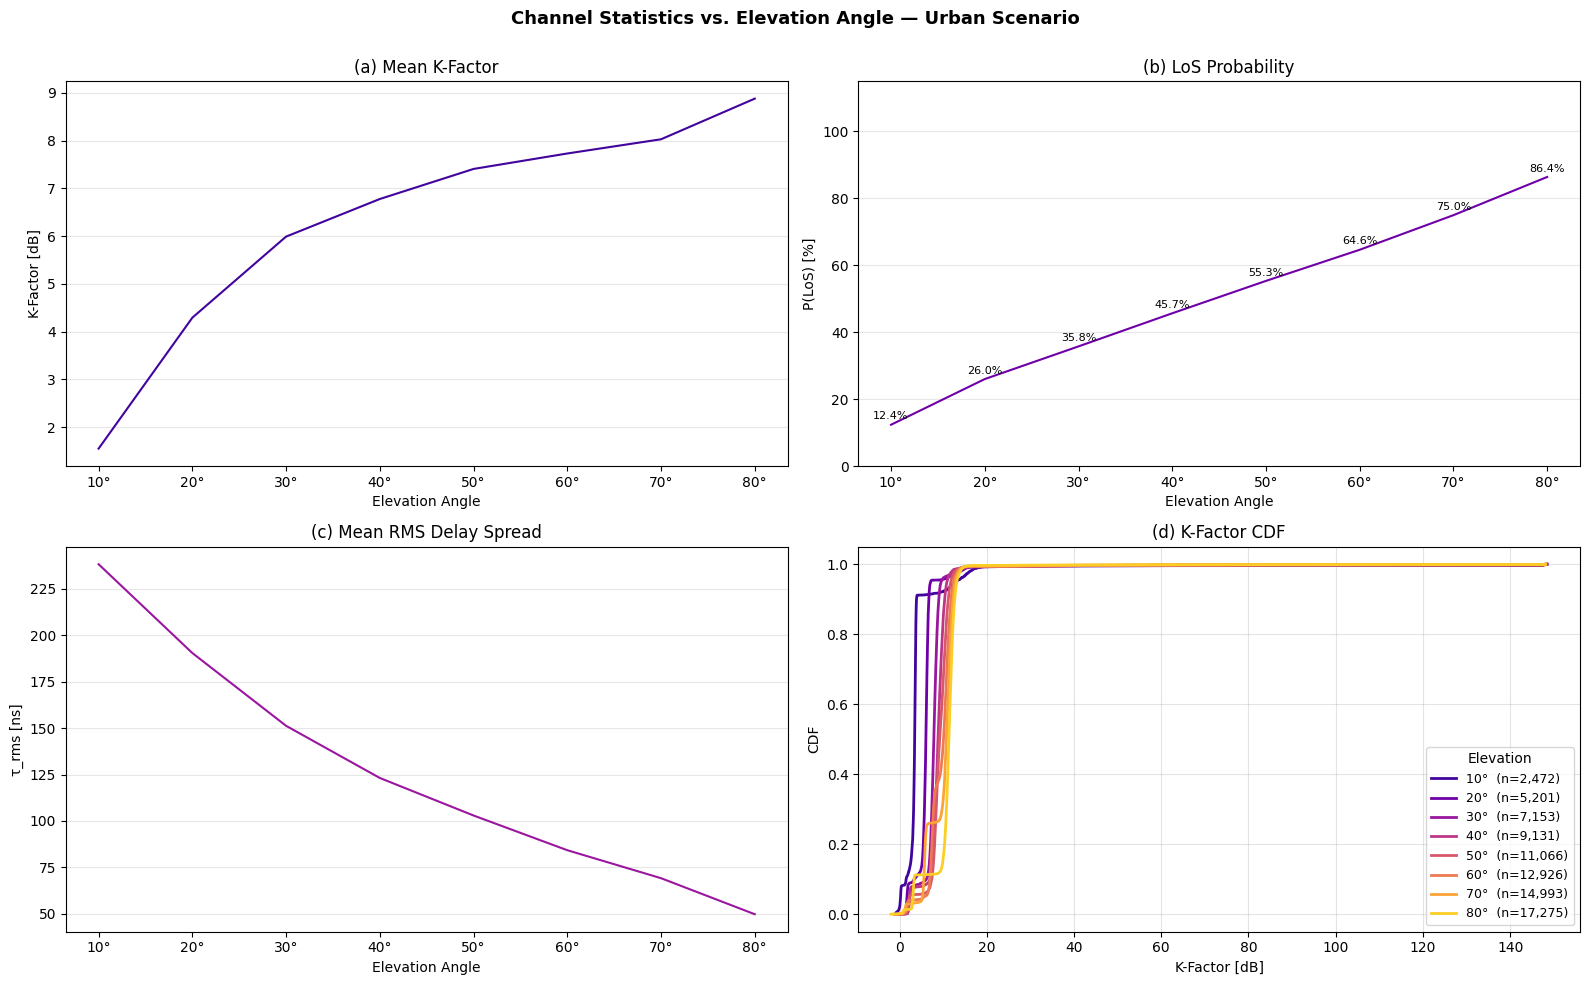

Saved -> ./urban_env_results_circ_pol/angle_comparison.png


In [12]:
if len(all_results) >= 2:
    fig    = plot_angle_comparison(all_results)
    _fname = os.path.join(OUTPUT_DIR, "angle_comparison.png")
    fig.savefig(_fname, dpi=150, bbox_inches='tight')
    plt.show()
    print(f"Saved -> {_fname}")
else:
    print("Need at least 2 completed elevation angles for comparison plot.")

## 10 - CIR Viewer

- Set `CIR_RX_IDX` to `'best_los'`, `'worst_los'`, or an integer index.
- Set `CIR_ANGLE` to the elevation angle you want to inspect.

In [ ]:
ang = sorted(all_results.keys())[2]

print(all_results[ang]["raw_results"][0].keys())

dict_keys(['rx_nominal', 'taus', 'amps', 'inter_d0', 'P_los', 'P_scat', 'P_specular', 'P_diffuse', 'P_diffraction', 'P_refraction', 'P_nlos', 'tau_rms_s', 'h_env', 'has_los'])


NLOS RX indices (full array) : [   2    3    4 ... 9997 9998 9999]
Valid NLOS RX options for CIR inspection : [799, 1199, 1599, 3199, 3599, 5199, 5599, 6399, 6799, 7199, 7999, 9999]
799


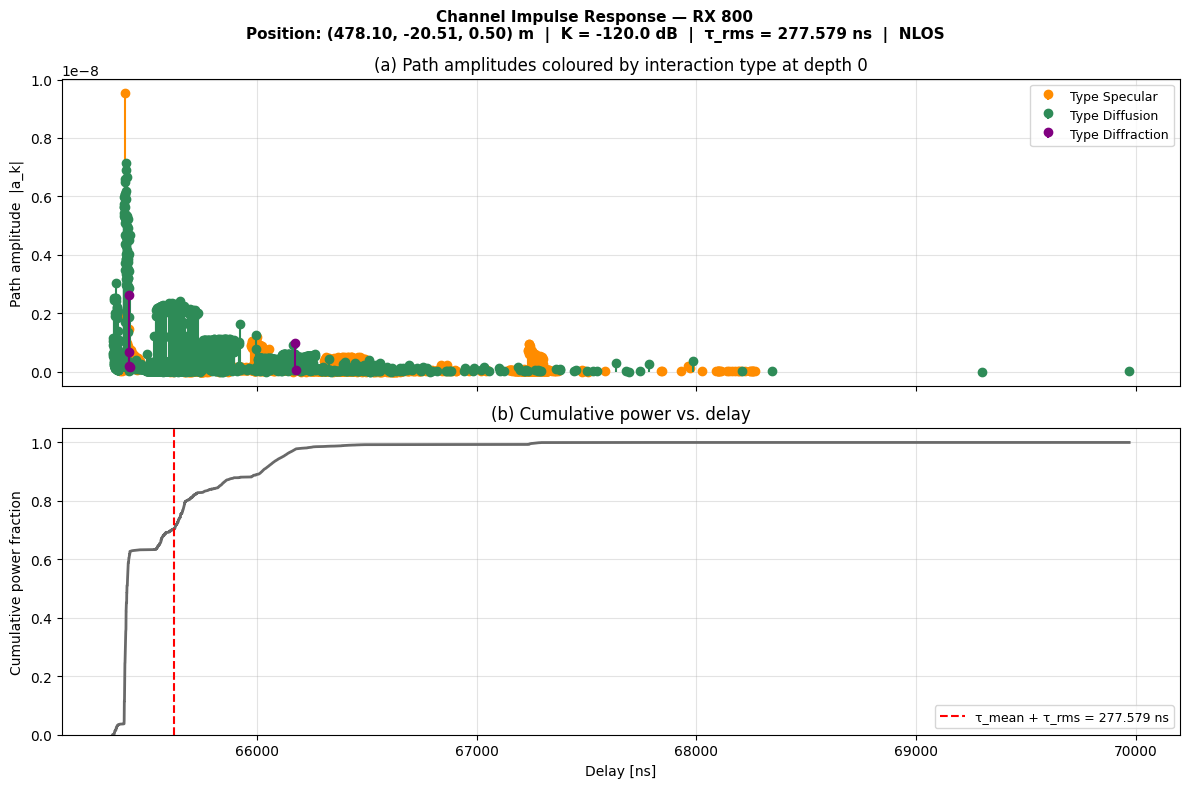

Saved -> ./urban_env_results_depth/cir_elev030deg_rx800.png
Total paths: 7056  |  LoS: 0  |  Scatter/diff: 7056


In [ ]:
CIR_ANGLE = sorted(all_results.keys())[1]

# ── Identify NLOS receivers ───────────────────────────────────────────────────
_res            = all_results[CIR_ANGLE]
_raw    = _res["raw_results"]
has_los         = np.asarray(_res["los_probability"], dtype=bool)
nlos_idx        = np.where(~has_los)[0]          # indices into the full rx array

valid_idx_options = [i for i in range(40000) if (i + 1) % RAW_SAVE_INTERVAL == 0]
valid_nlos_idx_options =[i for i in nlos_idx if (i + 1) % RAW_SAVE_INTERVAL == 0]
print(f"NLOS RX indices (full array) : {nlos_idx}")
print(f"Valid NLOS RX options for CIR inspection : {valid_nlos_idx_options}")
# ── Pick a receiver ───────────────────────────────────────────────────────────
# Integer → index into the NLOS subset  (0 … len(nlos_idx)-1)
# 'best_los'  → LoS raw result with highest  P_los / P_scat
# 'worst_los' → LoS raw result with lowest   P_los / P_scat


CIR_RX_IDX = valid_nlos_idx_options[0]  # <-- edit this

# CIR_RX_IDX = 'best_los'  # <-- edit this

# ── Shared arrays ─────────────────────────────────────────────────────────────
_K_pr   = np.array(_res["K_power_ratio"])
_tau_ns = np.array(_res["tau_rms_mean_s"]) * 1e9
_K_dB   = 10 * np.log10(_K_pr + 1e-12)
_raw    = _res["raw_results"]
_rx_pos = np.array(_res["nominal_rx_positions"])

# print(len(_raw))

if len(_raw) == 0:
    print("No raw_results available - decrease RAW_SAVE_INTERVAL and re-run.")
else:
    if CIR_RX_IDX == 'best_los':
        _cands = [r for r in _raw if r['has_los']] or _raw
        _r_inspect = max(_cands, key=lambda r: r['P_los'] / (r['P_scat'] + 1e-30))
    elif CIR_RX_IDX == 'worst_los':
        _cands = [r for r in _raw if r['has_los']] or _raw
        _r_inspect = min(_cands, key=lambda r: r['P_los'] / (r['P_scat'] + 1e-30))
    else:
        _r_inspect = _raw[np.where(valid_idx_options == CIR_RX_IDX)[0][0]]
        # _r_inspect = _raw[int(CIR_RX_IDX)]

    _nom    = np.array(_r_inspect["rx_nominal"])
    _dists  = np.linalg.norm(_rx_pos - _nom, axis=1)
    _rx_idx = int(np.argmin(_dists))
    print(_rx_idx)

    fig = plot_cir(
        raw_result = _r_inspect,
        rx_idx     = _rx_idx,
        K_dB       = _K_dB[_rx_idx],
        tau_rms_ns = _tau_ns[_rx_idx],
    )
    _fname = os.path.join(OUTPUT_DIR, f"cir_elev{int(CIR_ANGLE):03d}deg_rx" + str(_rx_idx+1) + ".png")
    fig.savefig(_fname, dpi=150, bbox_inches='tight')
    plt.show()
    print("Saved -> " + _fname)
    _id0       = np.array(_r_inspect['inter_d0'])
    _n_los     = int(np.sum(_id0 == 0))
    _n_scatter = len(_id0) - _n_los
    print("Total paths: " + str(len(_r_inspect['taus'])) +
          "  |  LoS: " + str(_n_los) +
          "  |  Scatter/diff: " + str(_n_scatter))

## 11 - PDP Realization per Elevation

One PDP realization per elevation angle. For each angle the first saved LoS
receiver is used (falls back to first NLOS if no LoS raw result exists).
Power is shown in dB relative to the strongest path.

In [ ]:
# ── PDP realization per elevation ──────────────────────────────────────────
angles_sorted = sorted(all_results.keys())
n_angles = len(angles_sorted)
n_cols = min(3, n_angles)
n_rows = math.ceil(n_angles / n_cols)

fig, axes = plt.subplots(n_rows, n_cols,
                          figsize=(6 * n_cols, 4.5 * n_rows),
                          squeeze=False)
fig.suptitle('PDP Realization per Elevation Angle', fontsize=14, fontweight='bold')

for ax_idx, elev in enumerate(angles_sorted):
    ax   = axes[ax_idx // n_cols][ax_idx % n_cols]
    _res = all_results[elev]
    _raw = _res['raw_results']

    if not _raw:
        ax.text(0.5, 0.5, 'No raw results\n(lower RAW_SAVE_INTERVAL)',
                ha='center', va='center', transform=ax.transAxes)
        ax.set_title(f'Elev = {int(elev)}°')
        continue

    # Pick best LoS realization; fall back to first entry
    los_entries = [r for r in _raw if r.get('has_los', False)]
    r = (max(los_entries, key=lambda r: r['P_los'] / (r['P_scat'] + 1e-30))
         if los_entries else _raw[0])

    taus_ns  = np.asarray(r['taus']) * 1e9          # delay in ns
    pwr_lin  = np.abs(np.asarray(r['amps'])) ** 2   # path power (linear)
    inter_d0 = np.asarray(r['inter_d0'], dtype=int)

    # Normalise to strongest path
    pwr_dB = 10 * np.log10(pwr_lin / (pwr_lin.max() + 1e-300) + 1e-300)

    # Colour by interaction type (0 = LoS, >0 = scatter/diffraction)
    clr_map = {0: 'steelblue'}
    scatter_clrs = ['darkorange', 'seagreen', 'purple', 'crimson', 'brown']
    for k, t in enumerate(np.unique(inter_d0[inter_d0 != 0])):
        clr_map[int(t)] = scatter_clrs[k % len(scatter_clrs)]

    for itype in np.unique(inter_d0):
        mask = inter_d0 == itype
        lbl  = 'LoS' if itype == 0 else f'Type {itype}'
        clr  = clr_map[itype]
        ml, sl, _ = ax.stem(taus_ns[mask], pwr_dB[mask],
                             linefmt=clr, markerfmt='o', basefmt=' ',
                             label=lbl)
        ml.set_color(clr); ml.set_markersize(5)
        plt.setp(sl, linewidth=1.4, color=clr)

    # Mark RMS delay spread
    tau_rms_ns = r['tau_rms_s'] * 1e9
    ax.axvline(taus_ns.min() + tau_rms_ns, color='red', linestyle='--',
               linewidth=1.3, label=f'τ_rms = {tau_rms_ns:.2f} ns')

    _K_dB = 10 * np.log10(r['P_los'] / (r['P_scat'] + 1e-30) + 1e-300)
    _type = 'LoS' if r.get('has_los') else 'NLOS'
    ax.set_title(f'Elev = {int(elev)}°  |  K = {_K_dB:.1f} dB  |  {_type}', fontsize=10)
    ax.set_xlabel('Delay [ns]')
    ax.set_ylabel('Relative power [dB]')
    ax.set_ylim(bottom=-50)
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.35)

# Hide unused axes
for ax_idx in range(n_angles, n_rows * n_cols):
    axes[ax_idx // n_cols][ax_idx % n_cols].set_visible(False)

plt.tight_layout()
_pdp_fname = os.path.join(OUTPUT_DIR, 'pdp_per_elevation.png')
fig.savefig(_pdp_fname, dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved -> {_pdp_fname}')


## 12 - Optional: Scene Preview (last solved geometry)

In [ ]:
VIS_ANGLE  = sorted(all_results.keys())[0]
VIS_RX_IDX = 0

_res_vis = all_results[VIS_ANGLE]
_tx_pos  = _res_vis["tx_pos"]
_rx_vis  = _res_vis["nominal_rx_positions"][VIS_RX_IDX]

print(f"Building scene for  elev={VIS_ANGLE:.0f} deg  RX #{VIS_RX_IDX+1} ...")
_scene_vis, _ = build_scene_batch([_rx_vis], _tx_pos, cfg)

_solver_vis = PathSolver()
_seed_vis   = drjit.cuda.ad.UInt(0)

_paths_vis = _solver_vis(
    scene                 = _scene_vis,
    max_depth             = MAX_DEPTH,
    los                   = LOS,
    specular_reflection   = SPECULAR_REFLECTION,
    diffuse_reflection    = DIFFUSE_REFLECTION,
    refraction            = REFRACTION,
    diffraction           = DIFFRACTION,
    edge_diffraction      = EDGE_DIFFRACTION,
    synthetic_array       = False,
    max_num_paths_per_src = 200,
    samples_per_src       = 50_000,
    seed                  = _seed_vis,
)

_amp_v, _tau_v = _paths_vis.cir(normalize_delays=False, out_type="numpy")
_valid = np.abs(_amp_v[0, 0, 0, 0, :, 0]) > 0
print(f"Paths found: {int(np.sum(_valid))}")
print(f"  Delays [ns]: {_tau_v[0,0,0,0,_valid][:10]*1e9}")